# Task 5 (Advanced) – Machine Learning Classification Model
**Goal:** classify Netflix titles as **Movie** or **TV Show** using the available features.

Workflow
1. Select and prepare features
2. Split data into training and testing sets
3. Train classification models
4. Evaluate model performance
5. Compare model accuracy

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 0. Load and inspect the data

In [2]:
DATA_PATH = "Dataset.csv"          # change the path if your file is elsewhere
df = pd.read_csv(r"D:\Ausify_internship_task\data\Dataset.csv")
print("Shape:", df.shape)
display(df.head()) if "display" in globals() else print(df.head())
print(df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nTarget distribution:\n", df["type"].value_counts())
print("\nDuplicate rows:", df.duplicated().sum())

Shape: (8790, 10)
  show_id     type                             title         director  \
0      s1    Movie              Dick Johnson Is Dead  Kirsten Johnson   
1      s3  TV Show                         Ganglands  Julien Leclercq   
2      s6  TV Show                     Midnight Mass    Mike Flanagan   
3     s14    Movie  Confessions of an Invisible Girl    Bruno Garotti   
4      s8    Movie                           Sankofa     Haile Gerima   

         country date_added  release_year rating  duration  \
0  United States  9/25/2021          2020  PG-13    90 min   
1         France  9/24/2021          2021  TV-MA  1 Season   
2  United States  9/24/2021          2021  TV-MA  1 Season   
3         Brazil  9/22/2021          2021  TV-PG    91 min   
4  United States  9/24/2021          1993  TV-MA   125 min   

                                           listed_in  
0                                      Documentaries  
1  Crime TV Shows, International TV Shows, TV Act...  
2    

Notes on the data:
* There are no `NaN`s, but missing values are stored as the string **"Not Given"** (director, country).
* The target is `type` (Movie = 6126, TV Show = 2664) – moderately imbalanced, so we will use a
  **stratified** split and report F1 / ROC-AUC besides accuracy.
* `duration` ("90 min" vs "2 Seasons") directly reveals the label (**data leakage**), so it is
  excluded from the main experiment. It is used later only to *demonstrate* the leakage.
.

## Step 1 – Select and prepare features

In [3]:
data = df.copy()

# --- date features 
data["date_added"] = pd.to_datetime(data["date_added"], errors="coerce")
data["year_added"] = data["date_added"].dt.year
data["month_added"] = data["date_added"].dt.month
data["years_to_netflix"] = (data["year_added"] - data["release_year"]).clip(lower=0)

# --- country: keep the first listed country, group rare ones into "Other" 
data["country"] = data["country"].replace("Not Given", np.nan)
data["main_country"] = data["country"].str.split(",").str[0].str.strip()
top_countries = data["main_country"].value_counts().head(15).index
data["main_country"] = data["main_country"].where(data["main_country"].isin(top_countries), "Other")
data["main_country"] = data["main_country"].fillna("Unknown")
data["n_countries"] = data["country"].fillna("").apply(lambda s: len([c for c in s.split(",") if c.strip()]))

# --- director: only keep whether it is known and how many directors 
data["has_director"] = (data["director"] != "Not Given").astype(int)
data["n_directors"] = data["director"].where(data["director"] != "Not Given", "").apply(
    lambda s: len([d for d in s.split(",") if d.strip()]))

# --- genres (listed_in): multi-hot encode the most common genres 
# IMPORTANT: many genre labels literally contain the answer ("TV Dramas", "International Movies",
# "Anime Series", "Stand-Up Comedy & Talk Shows" ...). We strip those Movie/TV words so that only the
# genuine genre information ("Dramas", "International", "Anime", ...) is kept.
import re
def clean_genre(g):
    g = g.strip()
    g = re.sub(r"\b(TV Shows|TV Show|Movies|Movie|Series|Features|TV)\b", "", g)
    g = re.sub(r"\s+", " ", g).strip(" &-'")
    g = {"Docuseries": "Documentaries", "Stand-Up Comedy": "Comedies", "Stand-Up Comedy & Talk": "Comedies",
         "Reality": "Reality", "Kids": "Children & Family", "Classic": "Classic", "Cult": "Cult"}.get(g, g)
    return g if g else "Other"

genres = data["listed_in"].str.split(",").apply(lambda xs: sorted({clean_genre(x) for x in xs}))
top_genres = pd.Series([g for xs in genres for g in xs]).value_counts().head(25).index
for g in top_genres:
    data["genre_" + g.replace(" ", "_").replace("&", "and")] = genres.apply(lambda xs, g=g: int(g in xs))
data["n_genres"] = genres.apply(len)

# --- rating: group the very rare categories 
data["rating"] = data["rating"].replace({"TV-Y7-FV": "TV-Y7", "NC-17": "R", "UR": "NR"})

# --- target 
y = (data["type"] == "TV Show").astype(int)        # 0 = Movie, 1 = TV Show
class_names = ["Movie", "TV Show"]

genre_cols = [c for c in data.columns if c.startswith("genre_")]
numeric_cols = ["release_year", "year_added", "month_added", "years_to_netflix",
                "n_countries", "n_directors", "has_director", "n_genres"] + genre_cols
categorical_cols = ["rating", "main_country"]

X = data[numeric_cols + categorical_cols].copy()
print("Feature matrix:", X.shape)
print("Numeric features    :", len(numeric_cols))
print("Categorical features:", categorical_cols)

Feature matrix: (8790, 35)
Numeric features    : 33
Categorical features: ['rating', 'main_country']


### Quick exploratory look at the selected features

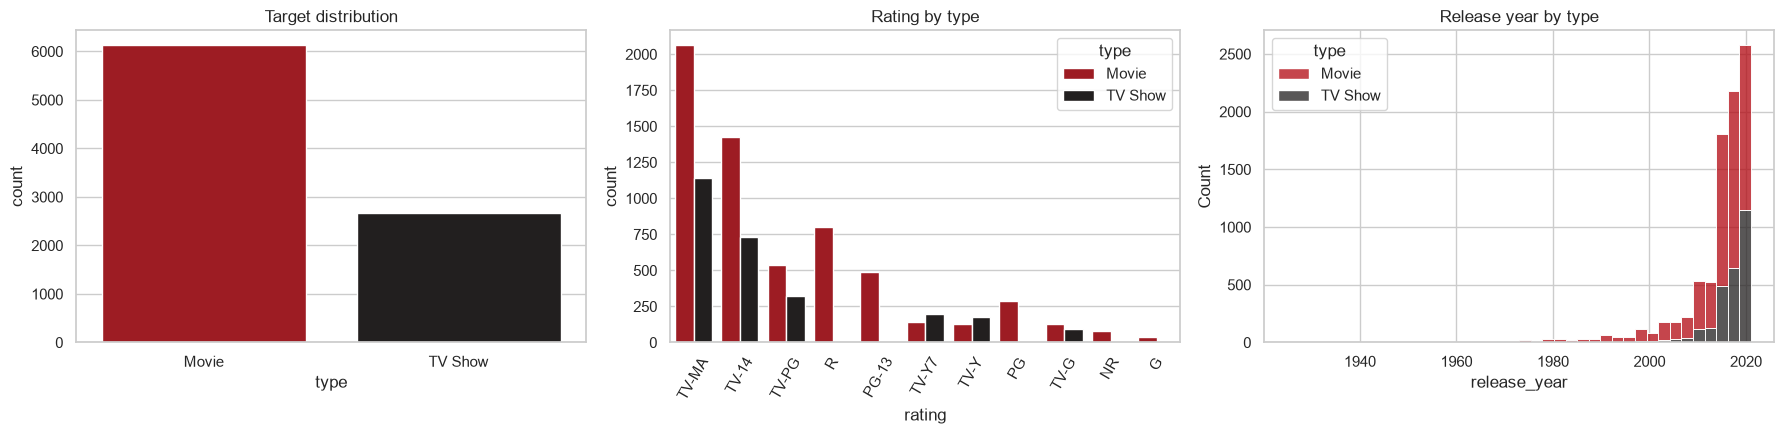

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.countplot(x="type", data=df, ax=axes[0], palette=["#b20710", "#221f1f"])
axes[0].set_title("Target distribution")

order = data["rating"].value_counts().index
sns.countplot(x="rating", hue="type", data=data, order=order, ax=axes[1], palette=["#b20710", "#221f1f"])
axes[1].set_title("Rating by type"); axes[1].tick_params(axis="x", rotation=60)

sns.histplot(data=data, x="release_year", hue="type", bins=40, multiple="stack", ax=axes[2],
             palette=["#b20710", "#221f1f"])
axes[2].set_title("Release year by type")
plt.tight_layout(); plt.show()

## Step 2 – Split into training and testing sets
80 % train / 20 % test, **stratified** so both sets keep the Movie / TV Show ratio.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("TV-Show share  train: %.3f   test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (7032, 35)  Test: (1758, 35)
TV-Show share  train: 0.303   test: 0.303


## Step 3 – Train classification models
Preprocessing (imputation, one-hot encoding, scaling) lives inside a `Pipeline`, so it is fitted
**only on the training data** – no leakage from the test set.

In [6]:
def make_preprocessor(num_cols, cat_cols, scale):
    from sklearn.impute import SimpleImputer
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])

models = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), True),
    "K-Nearest Neighbors": (KNeighborsClassifier(n_neighbors=15), True),
    "Decision Tree":       (DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE), False),
    "Random Forest":       (RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE), False),
    "Gradient Boosting":   (GradientBoostingClassifier(random_state=RANDOM_STATE), False),
}

fitted = {}
for name, (clf, scale) in models.items():
    pipe = Pipeline([("prep", make_preprocessor(numeric_cols, categorical_cols, scale)),
                     ("clf", clf)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    print(f"trained: {name}")

trained: Logistic Regression
trained: K-Nearest Neighbors
trained: Decision Tree
trained: Random Forest
trained: Gradient Boosting


## Step 4 – Evaluate model performance
Accuracy, precision, recall, F1 and ROC-AUC on the **test set**, plus 5-fold cross-validation on the
training set to check stability.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipe in fitted.items():
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, pipe.predict(X_train)),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "CV Mean Acc": cv_scores.mean(),
        "CV Std": cv_scores.std(),
    })

results = pd.DataFrame(rows).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)
print(results.round(4).to_string(index=False))

baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"\nMajority-class baseline accuracy: {baseline:.4f}")

              Model  Train Accuracy  Test Accuracy  Precision  Recall     F1  ROC-AUC  CV Mean Acc  CV Std
      Decision Tree          0.9753         0.9727     0.9602  0.9493 0.9547   0.9712       0.9727  0.0035
  Gradient Boosting          0.9735         0.9716     0.9497  0.9568 0.9533   0.9898       0.9724  0.0030
      Random Forest          0.9982         0.9704     0.9564  0.9456 0.9509   0.9904       0.9703  0.0033
Logistic Regression          0.9713         0.9681     0.9475  0.9475 0.9475   0.9906       0.9714  0.0021
K-Nearest Neighbors          0.9700         0.9681     0.9560  0.9381 0.9470   0.9844       0.9657  0.0038

Majority-class baseline accuracy: 0.6968


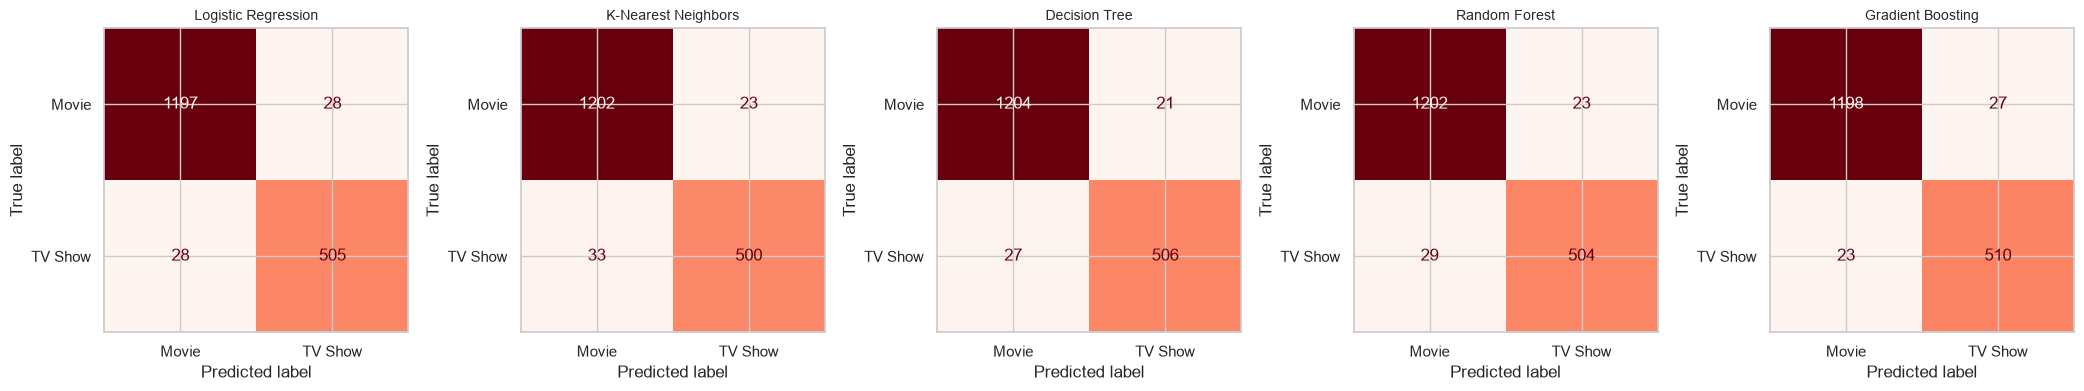


Classification report – best model: Decision Tree

              precision    recall  f1-score   support

       Movie       0.98      0.98      0.98      1225
     TV Show       0.96      0.95      0.95       533

    accuracy                           0.97      1758
   macro avg       0.97      0.97      0.97      1758
weighted avg       0.97      0.97      0.97      1758



In [8]:
# Detailed report + confusion matrices
fig, axes = plt.subplots(1, len(fitted), figsize=(4.2 * len(fitted), 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, display_labels=class_names,
                                          cmap="Reds", colorbar=False, ax=ax)
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

best_name = results.loc[0, "Model"]
print(f"\nClassification report – best model: {best_name}\n")
print(classification_report(y_test, fitted[best_name].predict(X_test), target_names=class_names))

## Step 5 – Compare model accuracy

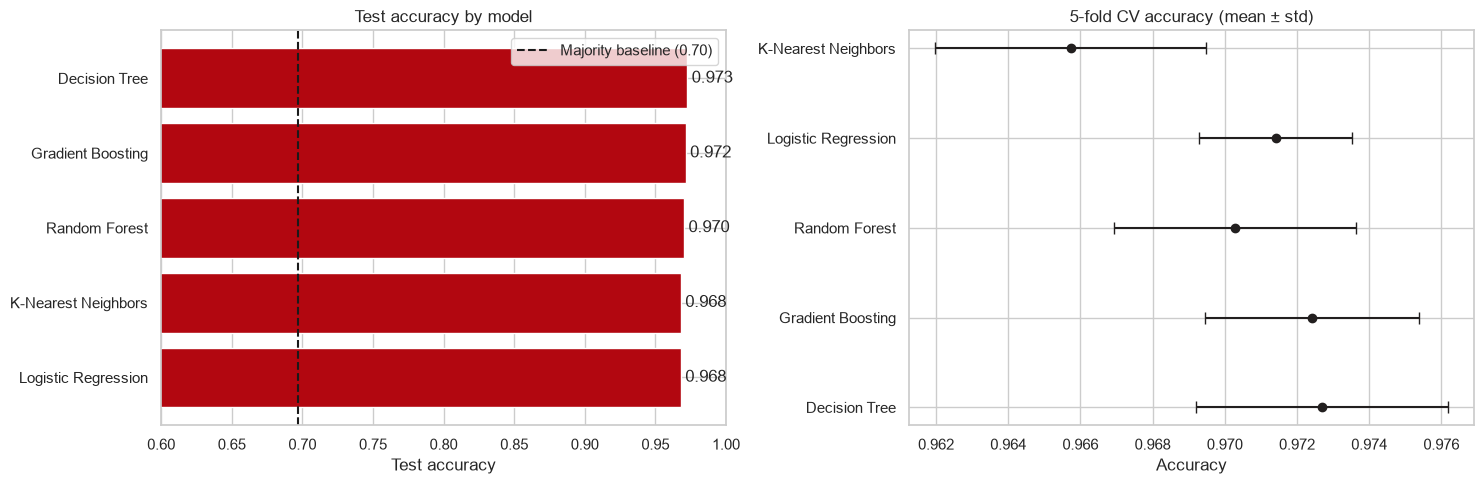

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

order = results.sort_values("Test Accuracy")
axes[0].barh(order["Model"], order["Test Accuracy"], color="#b20710")
axes[0].axvline(baseline, color="k", ls="--", label=f"Majority baseline ({baseline:.2f})")
axes[0].set_xlim(0.6, 1.0); axes[0].set_xlabel("Test accuracy"); axes[0].legend()
axes[0].set_title("Test accuracy by model")
for i, v in enumerate(order["Test Accuracy"]):
    axes[0].text(v + 0.003, i, f"{v:.3f}", va="center")

axes[1].errorbar(results["CV Mean Acc"], results["Model"], xerr=results["CV Std"],
                 fmt="o", color="#221f1f", capsize=4)
axes[1].set_title("5-fold CV accuracy (mean ± std)"); axes[1].set_xlabel("Accuracy")
plt.tight_layout(); plt.show()

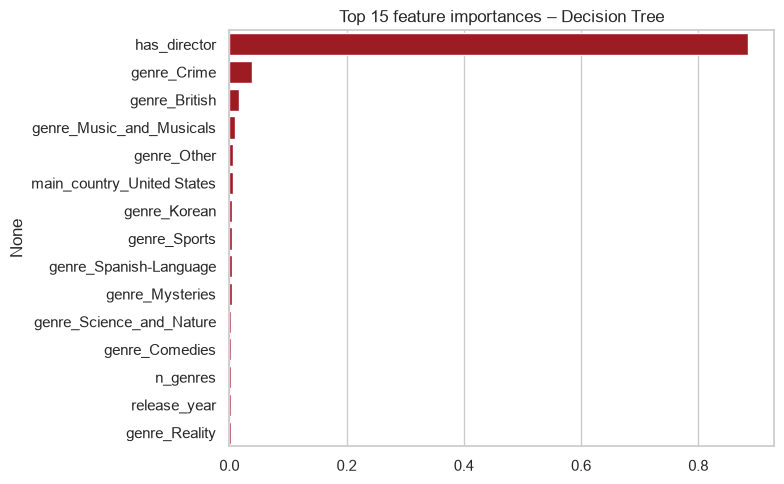

In [10]:
# Feature importance of the best tree-based model
tree_models = [n for n in ["Random Forest", "Gradient Boosting", "Decision Tree"] if n in fitted]
tree_best = results[results["Model"].isin(tree_models)].iloc[0]["Model"]
pipe = fitted[tree_best]
feat_names = pipe.named_steps["prep"].get_feature_names_out()
imp = pd.Series(pipe.named_steps["clf"].feature_importances_, index=feat_names).sort_values(ascending=False).head(15)
imp.index = [i.split("__", 1)[-1] for i in imp.index]

plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color="#b20710")
plt.title(f"Top 15 feature importances – {tree_best}")
plt.tight_layout(); plt.show()

### Optional: hyper-parameter tuning of the best model family

In [11]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([("prep", make_preprocessor(numeric_cols, categorical_cols, False)),
                 ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
grid = {"clf__n_estimators": [200, 400],
        "clf__max_depth": [None, 15, 25],
        "clf__min_samples_leaf": [1, 2, 4]}
gs = GridSearchCV(pipe, grid, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)
print("Best params :", gs.best_params_)
print("Best CV acc : %.4f" % gs.best_score_)
print("Test acc    : %.4f" % accuracy_score(y_test, gs.predict(X_test)))

Best params : {'clf__max_depth': 25, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 400}
Best CV acc : 0.9716
Test acc    : 0.9710


### Demonstration of data leakage: adding `duration`
`duration` is "xx min" for movies and "n Season(s)" for TV shows, so it gives away the answer.
A model that uses it scores ~100 %, which would be **misleading** – that is why it was excluded above.

In [12]:
X_leak = X.copy()
X_leak["duration_is_minutes"] = df["duration"].str.contains("min").astype(int)
Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    X_leak, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
leak_pipe = Pipeline([("prep", make_preprocessor(numeric_cols + ["duration_is_minutes"], categorical_cols, False)),
                      ("clf", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))])
leak_pipe.fit(Xl_train, yl_train)
print("Random Forest accuracy WITH duration (leaky): %.4f" % accuracy_score(yl_test, leak_pipe.predict(Xl_test)))

Random Forest accuracy WITH duration (leaky): 1.0000


## Conclusion

In [13]:
best = results.iloc[0]
print(f"Best model : {best['Model']}")
print(f"Test acc   : {best['Test Accuracy']:.4f}   F1: {best['F1']:.4f}   ROC-AUC: {best['ROC-AUC']:.4f}")
print(f"Baseline   : {baseline:.4f}")
results.to_csv("model_comparison_results.csv", index=False)
print("Saved model_comparison_results.csv")

Best model : Decision Tree
Test acc   : 0.9727   F1: 0.9547   ROC-AUC: 0.9712
Baseline   : 0.6968
Saved model_comparison_results.csv


## Task 5 Complete

# Thank You